# Homework 5 — Convolutional Neural Networks (PyTorch)
**CSCI1409 Deep Learning | Aidyn Abirov | Week 5**

Fill in every `# TODO`. Do **not** change the `assert` lines: they tell you when a cell is correct. Write your explanations in the **Your answer** cells.

- **Warm-up, Task 1, Task 2: no AI.** Task 3: AI allowed for explanations and debugging only (record which tool and what for).
- Save as `Surname_Firstname_Homework05.ipynb`, restart the kernel, **Run All**, and submit via Teams.

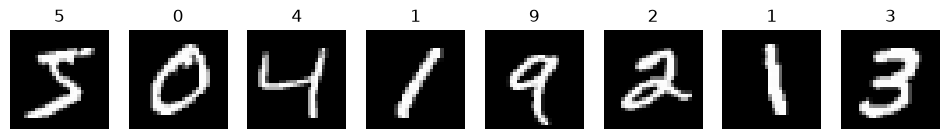

: 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

torch.manual_seed(0)

# MNIST: 28x28 grayscale handwritten digits (downloads about 12 MB the first time)
to_tensor = torchvision.transforms.ToTensor()
train_set = torchvision.datasets.MNIST("data", train=True, download=True, transform=to_tensor)
test_set = torchvision.datasets.MNIST("data", train=False, download=True, transform=to_tensor)
train_loader = torch.utils.data.DataLoader(train_set, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=1000)

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, i in zip(axes, range(8)):
    img, label = train_set[i]
    ax.imshow(img[0], cmap="gray"); ax.set_title(label); ax.axis("off")
plt.show()

## Warm-up — PyTorch in 10 minutes (no AI)
This is your first PyTorch homework. Run each cell, read the comments, and fill in the small TODOs.

**1. Tensors and shapes.** A tensor is PyTorch's version of a NumPy array. A batch of images always has shape **(batch, channels, height, width)**.

In [5]:
x = torch.tensor([[1., 2., 3.],
                  [4., 5., 6.]])
print(x.shape)            # torch.Size([2, 3])
print(x[0], x[:, 1])      # first row, second column

images, labels = next(iter(train_loader))
print(images.shape)       # (64, 1, 28, 28): 64 images, 1 channel (grayscale), 28x28 pixels
print(labels.shape)       # (64,): one label per image

# TODO: create a batch of 4 grayscale 28x28 images filled with zeros
fake_batch = torch.zeros(4,1,28,28)
assert fake_batch.shape == (4, 1, 28, 28)

torch.Size([2, 3])
tensor([1., 2., 3.]) tensor([2., 5.])
torch.Size([64, 1, 28, 28])
torch.Size([64])


**2. Automatic gradients.** In Homework 4 you used $L(w) = (w^2-1)^2$ with gradient $g(w) = 4w^3 - 4w$. PyTorch can compute that gradient for you.

In [6]:
w = torch.tensor(2.0, requires_grad=True)   # "track gradients for w"
L = (w**2 - 1)**2
L.backward()                                # compute dL/dw
print(w.grad)                               # 4*8 - 4*2 = 24

# TODO: repeat for w = 1.5 and store the gradient in grad_15
w2 = torch.tensor(1.5, requires_grad = True)
L_15 = (w2**2 -1)**2 
L_15.backward()
grad_15 = w2.grad
print(w2.grad)
assert torch.isclose(grad_15, torch.tensor(7.5))   # the same value as in Homework 4

tensor(24.)
tensor(7.5000)


**3. One gradient-descent step with an optimizer.** `torch.optim.SGD` does exactly the update $w \leftarrow w - \eta\, g$ from Homework 4.

In [7]:
w = torch.tensor(1.5, requires_grad=True)
optimizer = torch.optim.SGD([w], lr=0.1)

L = (w**2 - 1)**2
optimizer.zero_grad()   # 1. clear any old gradient
L.backward()            # 2. compute the new gradient (7.5)
optimizer.step()        # 3. w <- w - lr * gradient
print(w.item())         # 1.5 - 0.1 * 7.5 = 0.75, the same as your Homework 4 hand update

0.75


**Question W.** In your own words, what does each of `zero_grad()`, `backward()`, and `step()` do?

**Your answer:** 
zero_grad() clears the gradients from previous updates, because PyTorch adds new gradients to the old ones.
backward() calculates the gradients of the loss with respect to the model parameters using backpropagation.
step() updates the model parameters using the calculated gradients and the learning rate. The goal is to reduce the loss.

## Task 1 — Convolution by hand and from scratch (no AI, about 30 minutes)

**1a. By hand.** Slide the 3×3 kernel over the 5×5 image (no padding, stride 1). At each position, multiply the overlapping numbers and add them up. Write the 3×3 result on paper, then type it into `hand_result`.

```
image                 kernel
0 0 0 0 0             -1  0  1
0 1 1 1 0             -1  0  1
0 1 1 1 0             -1  0  1
0 1 1 1 0
0 0 0 0 0
```

In [ ]:
image = torch.tensor([[0, 0, 0, 0, 0],
                      [0, 1, 1, 1, 0],
                      [0, 1, 1, 1, 0],
                      [0, 1, 1, 1, 0],
                      [0, 0, 0, 0, 0]], dtype=torch.float32)
kernel = torch.tensor([[-1, 0, 1],
                       [-1, 0, 1],
                       [-1, 0, 1]], dtype=torch.float32)

# TODO: type the 3x3 result you computed by hand
hand_result = torch.tensor([[2., 0., -2.],
                            [3., 0., -3.],
                            [2.,0.,-2.]])

In [9]:
def conv2d_scratch(image, kernel):
    H, W = image.shape
    k = kernel.shape[0]
    out = torch.zeros(H - k + 1, W - k + 1)
    for i in range(H - k + 1):
        for j in range(W - k + 1):
            total = 0.
            for a in range(k):
                for b in range(k):
                    total += image[i+a, j+b]*kernel[a,b]
            out[i,j] = total # replace this line
    return out
outt = conv2d_scratch(image, kernel).shape
print(outt)
mine = conv2d_scratch(image, kernel)
torch_out = F.conv2d(image[None, None], kernel[None, None])[0, 0]   # PyTorch wants (batch, channels, H, W)
print(mine); print(torch_out)
assert torch.allclose(mine, hand_result), "your function differs from your hand calculation"
assert torch.allclose(mine, torch_out), "your function differs from F.conv2d"

torch.Size([3, 3])
tensor([[ 2.,  0., -2.],
        [ 3.,  0., -3.],
        [ 2.,  0., -2.]])
tensor([[ 2.,  0., -2.],
        [ 3.,  0., -3.],
        [ 2.,  0., -2.]])


**1c. Output size.** For input size $n$, kernel size $k$, padding $p$, and stride $s$:
$$\text{output size} = \left\lfloor \frac{n + 2p - k}{s} \right\rfloor + 1$$
First fill in the last column of this table by hand. Then complete the function and run the check.

| $n$ | $k$ | $p$ | $s$ | output size |
|---|---|---|---|---|
| 5 | 3 | 0 | 1 |3 |
| 5 | 3 | 1 | 1 |5 |
| 5 | 3 | 0 | 2 |2 |
| 28 | 3 | 1 | 1 |28 |
| 28 | 5 | 0 | 1 |24|
| 28 | 3 | 1 | 2 | 14|

In [10]:
def conv_output_size(n, k, p, s):
    return ((n + 2 * p -k)//s)+1
print()
for n, k, p, s in [(5, 3, 0, 1), (5, 3, 1, 1), (5, 3, 0, 2), (28, 3, 1, 1), (28, 5, 0, 1), (28, 3, 1, 2)]:
    real = F.conv2d(torch.zeros(1, 1, n, n), torch.zeros(1, 1, k, k), padding=p, stride=s).shape[-1]
    print(f"n={n:2d} k={k} p={p} s={s}: formula {conv_output_size(n, k, p, s)}, PyTorch {real}")
    assert conv_output_size(n, k, p, s) == real


n= 5 k=3 p=0 s=1: formula 3, PyTorch 3
n= 5 k=3 p=1 s=1: formula 5, PyTorch 5
n= 5 k=3 p=0 s=2: formula 2, PyTorch 2
n=28 k=3 p=1 s=1: formula 28, PyTorch 28
n=28 k=5 p=0 s=1: formula 24, PyTorch 24
n=28 k=3 p=1 s=2: formula 14, PyTorch 14


**1d. Kernels on a real digit.** Create a horizontal-edge kernel (hint: the transpose of the vertical one) and a 3×3 blur kernel (every entry $1/9$). The code then applies all three kernels to a test digit with `padding=1` and shows the feature maps.

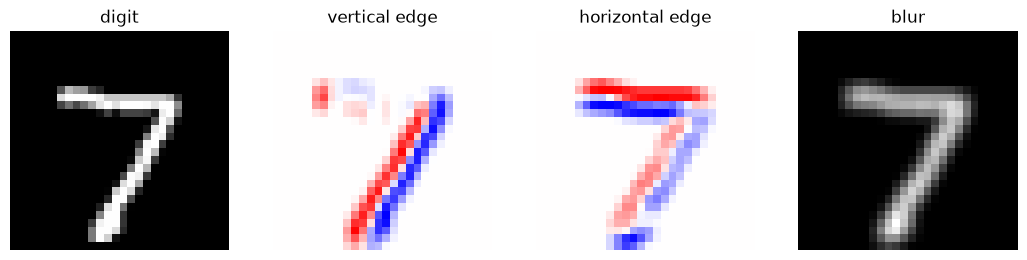

In [11]:
digit = test_set[0][0]          # shape (1, 28, 28)

vertical = kernel
horizontal = vertical.T             # TODO
blur = torch.full((3,3), (1/9))     # TODO

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
axes[0].imshow(digit[0], cmap="gray"); axes[0].set_title("digit")
for ax, (name, kern) in zip(axes[1:], [("vertical edge", vertical), ("horizontal edge", horizontal), ("blur", blur)]):
    fmap = F.conv2d(digit[None], kern[None, None], padding=1)[0, 0]
    assert fmap.shape == (28, 28)
    ax.imshow(fmap, cmap="bwr", vmin=-3, vmax=3) if "edge" in name else ax.imshow(fmap, cmap="gray"); ax.set_title(name)
for ax in axes: ax.axis("off")
plt.show()

**Questions 1.**
1. In your hand result, which positions are positive, which are negative, and which are zero? Explain using the left and right edges of the bright square.
2. Which strokes of the digit does each edge kernel light up? What does the blur kernel do?
3. Why is the result in 1a 3×3 and not 5×5? What does `padding=1` change?

**Your answer:**
1.The positive values appear where the kernel detects the left edge of the bright square. The negative values appear at the right edge. The middle is zero because the positive and negative contributions cancel each other.
2.
    The vertical-edge kernel highlights the left and right edges of the digit, especially along its diagonal stroke.
    The horizontal-edge kernel highlights the top horizontal stroke of the digit 7.
    The blur kernel smooths the image by averaging nearby pixels. It makes the edges softer and reduces small details.
3.The output is 3×3 because we use a 3×3 kernel on a 5×5 image without padding and with stride 1. The kernel can only move to 3 positions horizontally and 3 positions vertically.
With padding=1, one extra row and column of zeros are added to each side of the image. This allows the kernel to cover the border positions, so the output size becomes 5×5.

## Task 2 — Pooling, shapes, and parameter counts (no AI, about 20 minutes)

**2a. Max pooling by hand.** Split the 4×4 grid into 2×2 blocks (stride 2) and keep the largest number in each block. Type your 2×2 result into `hand_pool`, then complete `maxpool_scratch` (do not call `F.max_pool2d` inside it).

```
1 3 2 0
4 6 1 1
0 2 5 7
1 0 3 2
```

In [12]:
grid = torch.tensor([[1, 3, 2, 0],
                     [4, 6, 1, 1],
                     [0, 2, 5, 7],
                     [1, 0, 3, 2]], dtype=torch.float32)

# TODO: type your 2x2 hand result
hand_pool = torch.tensor([[6., 2.],
                          [2., 7.]])

def maxpool_scratch(x, size=2):
    H, W = x.shape
    out = torch.zeros(H // size, W // size)
    for i in range(H // size):
        for j in range(W // size):
            # TODO: take the size x size block for output position (i, j) and keep its maximum
            block = x[i*size : i*size+size, j*size : j * size + size]
            out[i, j] = torch.max(block)   # replace this line
    return out

mine = maxpool_scratch(grid)
torch_out = F.max_pool2d(grid[None, None], 2)[0, 0]
print(mine); print(torch_out)
assert torch.allclose(mine, hand_pool) and torch.allclose(mine, torch_out)

tensor([[6., 2.],
        [2., 7.]])
tensor([[6., 2.],
        [2., 7.]])


**2b. Trace the shapes.** Here is the CNN you will train in Task 3. For **one** input image of shape (1, 1, 28, 28), fill in this table **by hand** first: the output shape after each layer and the number of trainable parameters in that layer.

Parameters of `Conv2d(c_in, c_out, k)`: $c_{out} \times c_{in} \times k \times k$ weights $+\ c_{out}$ biases. Parameters of `Linear(n_in, n_out)`: $n_{in} \times n_{out} + n_{out}$.

| layer | output shape | parameters |
|---|---|---|
| Conv2d(1, 8, 3, padding=1) |(1,8,28,28) |80 |
| ReLU |(1,8,28,28) |0 |
| MaxPool2d(2) |(1,8,14,14) |0 |
| Conv2d(8, 16, 3, padding=1) |(1,16,14,14) |1168 |
| ReLU |(1,16,14,14) |0 |
| MaxPool2d(2) |(1,16,7,7) |0 |
| Flatten |(1,784) |0 |
| Linear(784, 10) |(1,10) |7850 |

In [13]:
cnn = nn.Sequential(
    nn.Conv2d(1, 8, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(8, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(16 * 7 * 7, 10),
)

# TODO: copy your table into these two lists (8 entries each, in order)
my_shapes = [
    (1, 8, 28, 28),
    (1, 8, 28, 28),
    (1, 8, 14, 14),
    (1, 16, 14, 14),
    (1, 16, 14, 14),
    (1, 16, 7, 7),
    (1, 784),
    (1, 10),
]
my_params = [80, 0, 0, 1168, 0, 0, 0, 7850]

x = torch.zeros(1, 1, 28, 28)
for layer, expected_shape, expected_params in zip(cnn, my_shapes, my_params):
    x = layer(x)
    n_params = sum(p.numel() for p in layer.parameters())
    print(f"{layer.__class__.__name__:10s} {str(tuple(x.shape)):18s} params = {n_params}")
    assert tuple(x.shape) == expected_shape, f"shape after {layer} is wrong in your table"
    assert n_params == expected_params, f"parameter count of {layer} is wrong in your table"
assert len(my_shapes) == len(my_params) == 8, "fill in all 8 rows"
print("total parameters:", sum(my_params))

Conv2d     (1, 8, 28, 28)     params = 80
ReLU       (1, 8, 28, 28)     params = 0
MaxPool2d  (1, 8, 14, 14)     params = 0
Conv2d     (1, 16, 14, 14)    params = 1168
ReLU       (1, 16, 14, 14)    params = 0
MaxPool2d  (1, 16, 7, 7)      params = 0
Flatten    (1, 784)           params = 0
Linear     (1, 10)            params = 7850
total parameters: 9098


**2c. CNN vs MLP.** This MLP also classifies 28×28 digits. Compute its parameter count **by hand**, type it in, and compare with the CNN.

In [14]:
mlp = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 128),
    nn.ReLU(),
    nn.Linear(128, 10),
)

mlp_params_by_hand = 101770 # TODO
mlp_params = sum(p.numel() for p in mlp.parameters())
assert mlp_params_by_hand == mlp_params
print(f"MLP: {mlp_params} parameters, CNN: {sum(my_params)} parameters, ratio {mlp_params / sum(my_params):.1f}x")

MLP: 101770 parameters, CNN: 9098 parameters, ratio 11.2x


**Questions 2.**
1. What does max pooling keep, and what does it throw away? Why does it make the next layer cheaper?
2. The first conv layer looks at all 784 pixels but has only 80 parameters. How is that possible? (Hint: think about how the same kernel is used at every position.)

**Your answer:**
1.Max pooling keeps the largest value from each 2×2 region. It throws away the smaller values and some information about their exact positions.It makes the feature maps smaller. For example, a 28×28 feature map becomes 14×14. This reduces the number of values that the next layer processes, so it needs fewer calculations.
2.The convolutional layer uses 8 filters of size 3×3. Each filter has 9 weights and 1 bias, so the total is 8 × (9 + 1) = 80 parameters.The same filters are reused at every position of the image. This is called weight sharing. Because of this, the layer can process all 784 pixels without learning separate weights for every position.

## Task 3 — Train a CNN on MNIST (AI allowed, about 40 minutes)
AI may be used to explain concepts or help debug this task only. Record which tool you used and for what, and be ready to explain every line.

**3a. The model.** Write the same CNN as in Task 2, but as a class. Create the layers in `__init__` and connect them in `forward`.

In [15]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # TODO: create conv1 (1 -> 8 channels), conv2 (8 -> 16 channels), both 3x3 with padding=1,
        #       one MaxPool2d(2) layer called pool, and fc = Linear(16 * 7 * 7, 10)
        self.conv1 = nn.Conv2d(1, 8, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(8, 16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.fc = nn.Linear(16 * 7 * 7, 10)
    def forward(self, x):
        # TODO: conv1 -> ReLU -> pool -> conv2 -> ReLU -> pool -> flatten -> fc
        #       use F.relu(...) for ReLU and x.flatten(1) to flatten everything except the batch dimension
        x = self.conv1(x)
        x = F.relu(x)
        x = self.pool(x)
        x = self.conv2(x)
        x = F.relu(x)
        x = self.pool(x)
        x = x.flatten(1)
        x = self.fc(x)
        return x

model = SmallCNN()
assert model(torch.zeros(5, 1, 28, 28)).shape == (5, 10), "output should be (batch, 10)"
assert sum(p.numel() for p in model.parameters()) == sum(my_params), "parameter count should match Task 2"
print("SmallCNN OK")

SmallCNN OK


**3b. Accuracy and training.** Complete `accuracy` (one line) and the five TODO lines in `train`. Each update uses a **mini-batch** of 64 images instead of all 60,000 — this is called stochastic gradient descent (SGD), and it is the same update as Homework 4, just with a gradient estimated from a small batch.

In [16]:
def accuracy(model, loader):
    model.eval()
    correct = 0
    with torch.no_grad():                       # no gradients needed for evaluation
        for images, labels in loader:
            logits = model(images)              # shape (batch, 10)
            predictions = torch.argmax(logits, dim=1)                # TODO: index of the largest logit in each row (hint: argmax)
            correct += (predictions == labels).sum().item()
    return correct / len(loader.dataset)

def train(model, epochs=2, lr=0.1):
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    losses = []
    for epoch in range(epochs):
        model.train()
        for images, labels in train_loader:
            logits = model(images)
            loss = F.cross_entropy(logits, labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
        print(f"epoch {epoch + 1}: test accuracy {accuracy(model, test_loader):.4f}")
    return losses

**3c. Train both models.** Training takes about a minute on a laptop CPU. The MLP from Task 2 is the baseline.

CNN
epoch 1: test accuracy 0.9736
epoch 2: test accuracy 0.9792
MLP
epoch 1: test accuracy 0.9250
epoch 2: test accuracy 0.9475
CNN: 0.9792 with 9098 parameters
MLP: 0.9475 with 101770 parameters


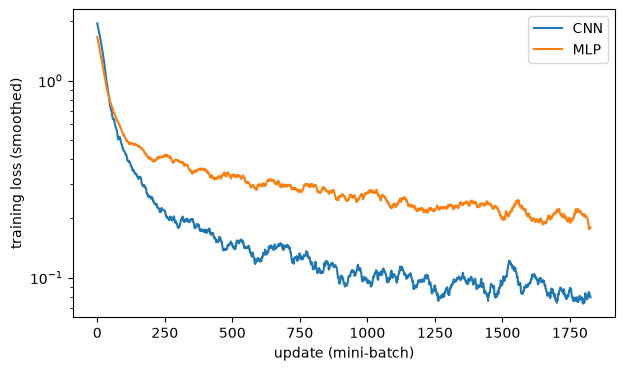

In [17]:
torch.manual_seed(0)
cnn_model = SmallCNN()
print("CNN"); cnn_losses = train(cnn_model)

torch.manual_seed(0)
mlp_model = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))
print("MLP"); mlp_losses = train(mlp_model)

cnn_acc, mlp_acc = accuracy(cnn_model, test_loader), accuracy(mlp_model, test_loader)
print(f"CNN: {cnn_acc:.4f} with {sum(p.numel() for p in cnn_model.parameters())} parameters")
print(f"MLP: {mlp_acc:.4f} with {sum(p.numel() for p in mlp_model.parameters())} parameters")
assert cnn_acc > 0.97, "the CNN should reach above 97% test accuracy; check your training loop"

smooth = lambda v: np.convolve(v, np.ones(50) / 50, mode="valid")   # moving average over 50 batches
plt.figure(figsize=(7, 4))
plt.plot(smooth(cnn_losses), label="CNN"); plt.plot(smooth(mlp_losses), label="MLP")
plt.xlabel("update (mini-batch)"); plt.ylabel("training loss (smoothed)"); plt.yscale("log"); plt.legend(); plt.show()

**3d. Look inside the CNN.** The three plots below show (1) the 8 learned first-layer filters, (2) what those filters produce for one test digit, and (3) test digits the CNN got wrong. Just run the cells and study the pictures.

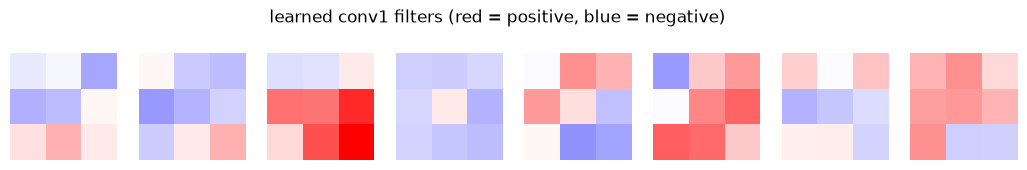

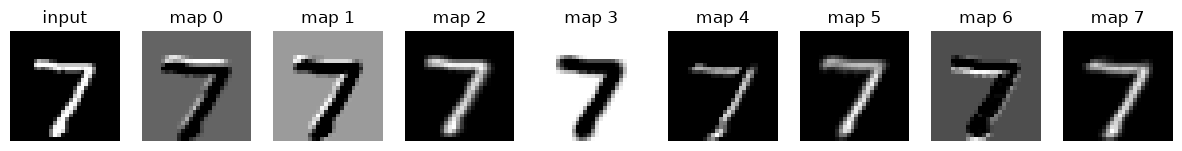

In [18]:
filters = cnn_model.conv1.weight.detach()          # shape (8, 1, 3, 3)
fig, axes = plt.subplots(1, 8, figsize=(13, 2))
for ax, f in zip(axes, filters):
    m = filters.abs().max()
    ax.imshow(f[0], cmap="bwr", vmin=-m, vmax=m); ax.axis("off")
fig.suptitle("learned conv1 filters (red = positive, blue = negative)"); plt.show()

with torch.no_grad():
    fmaps = F.relu(cnn_model.conv1(digit[None]))[0]   # shape (8, 28, 28)
fig, axes = plt.subplots(1, 9, figsize=(15, 2))
axes[0].imshow(digit[0], cmap="gray"); axes[0].set_title("input")
for k, ax in enumerate(axes[1:]):
    ax.imshow(fmaps[k], cmap="gray"); ax.set_title(f"map {k}")
for ax in axes: ax.axis("off")
plt.show()

208 of 10000 test digits misclassified


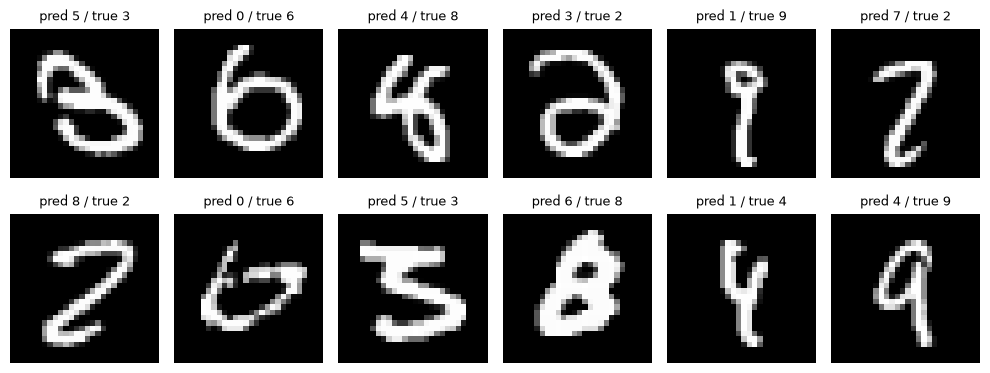

In [19]:
wrong_images, wrong_pred, wrong_true = [], [], []
with torch.no_grad():
    for images, labels in test_loader:
        preds = cnn_model(images).argmax(dim=1)
        mask = preds != labels
        wrong_images.append(images[mask]); wrong_pred.append(preds[mask]); wrong_true.append(labels[mask])
wrong_images, wrong_pred, wrong_true = torch.cat(wrong_images), torch.cat(wrong_pred), torch.cat(wrong_true)
print(f"{len(wrong_images)} of {len(test_set)} test digits misclassified")

fig, axes = plt.subplots(2, 6, figsize=(10, 4))
for ax, img, p, t in zip(axes.ravel(), wrong_images, wrong_pred, wrong_true):
    ax.imshow(img[0], cmap="gray"); ax.set_title(f"pred {p.item()} / true {t.item()}", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

**Questions 3.**
1. Compare the CNN and the MLP: test accuracy and number of parameters. Which uses its parameters better, and why?
2. Do any learned filters look like the edge kernels from Task 1? In the feature maps, which parts of the digit light up?
3. Look at the misclassified digits. Would you have got them right? What do the mistakes have in common?

**Your answer:**
1.My CNN reached 97.92% test accuracy with 9,098 parameters. My MLP reached 94.75% accuracy with 101,770 parameters.The CNN uses its parameters better because it achieves higher accuracy with about 11.2 times fewer parameters. CNN filters are shared across the image and can learn local patterns like edges.
2.Yes, some learned filters look similar to edge-detection kernels because they have positive and negative weights in different parts of the filter.In the feature maps of digit 7, the top horizontal stroke, diagonal line, and some edges and corners light up. Different filters respond to different parts of the same digit.
3.I think I could recognize some of the misclassified digits, but several are difficult even for a person.For example, some 3s look like 5s, and some 6s look like 0s. Most mistakes have unusual handwriting, unclear shapes, or strokes that make the digit look like another number.

**Optional (not required).** Shift every test image 3 pixels to the right with `torch.roll(images, shifts=3, dims=3)` and measure the accuracy of both models on the shifted images. Which model is more robust to the shift, and why?

In [ ]:
# Optional: your code here

## Submission checklist
- [ ] Every `# TODO` filled, every `assert` passes, **Kernel → Restart & Run All** works
- [ ] All **Your answer** cells written (W, 1, 2, 3)
- [ ] Warm-up, Tasks 1–2 done without AI; references listed
- [ ] Task 3 AI use recorded (tool + what for), or "no AI used"

**References / AI use:** to understand pytorch and see what i can write with pytorch also to see where i go wrong. Chating to better understand some formulas and way to write code right